In [1]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from src.data.io_utils import read_tif_image, convert_image_to_array

# Chemins des patches
images_patches = Path("/mnt/x/donnees/pachs_64_3classes/images")
masks_patches = Path("/mnt/x/donnees/pachs_64_3classes/masks")

print(f"Images patches: {images_patches.exists()}")
print(f"Masks patches: {masks_patches.exists()}")

Images patches: True
Masks patches: True


In [2]:
image_files = sorted(images_patches.glob("*.tif"))
mask_files = sorted(masks_patches.glob("*.tif"))

print(f"Nombre de patches images: {len(image_files)}")
print(f"Nombre de patches masks: {len(mask_files)}")

if len(image_files) > 0:
    print(f"Premiers patches: {[f.name for f in image_files[:5]]}")

Nombre de patches images: 19657
Nombre de patches masks: 19657
Premiers patches: ['sample_001000001.tif', 'sample_001000002.tif', 'sample_001000003.tif', 'sample_001000004.tif', 'sample_001000005.tif']


In [4]:
def show_patch_3class(image_path, mask_path, slice_idx=None):
    """
    Affiche un patch avec ses 3 classes
    """
    # Charger
    image_sitk = read_tif_image(str(image_path))
    mask_sitk = read_tif_image(str(mask_path))
    
    image = convert_image_to_array(image_sitk)  # (Z, Y, X)
    mask = convert_image_to_array(mask_sitk)
    
    if slice_idx is None:
        slice_idx = image.shape[0] // 2
    
    # Normaliser l'image
    img_slice = image[slice_idx, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    
    mask_slice = mask[slice_idx, :, :]
    
    # Créer le mask RGB
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]      # Fond: noir
    rgb_mask[mask_slice == 1] = [1, 0, 0]      # Neurones: rouge
    rgb_mask[mask_slice == 2] = [0, 1, 0]      # Vaisseaux: vert
    
    # Superposition
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[mask_slice == 1, 0] = 1
    overlay[mask_slice == 1, 1] = 0
    overlay[mask_slice == 1, 2] = 0
    overlay[mask_slice == 2, 0] = 0
    overlay[mask_slice == 2, 1] = 1
    overlay[mask_slice == 2, 2] = 0
    
    # Affichage
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title(f'Image - Slice {slice_idx}')
    axes[0].axis('off')
    
    axes[1].imshow(rgb_mask)
    axes[1].set_title('Mask 3 Classes')
    axes[1].axis('off')
    
    axes[2].imshow(overlay)
    axes[2].set_title('Superposition')
    axes[2].axis('off')
    
    # Légende
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='black', label='Fond (0)'),
        Patch(facecolor='red', label='Neurones (1)'),
        Patch(facecolor='green', label='Vaisseaux (2)')
    ]
    axes[2].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
    
    plt.suptitle(f'{image_path.name}')
    plt.tight_layout()
    plt.show()
    
    # Statistiques
    print(f"Statistiques du patch:")
    print(f"  Classe 0 (Fond): {(mask == 0).sum():,}")
    print(f"  Classe 1 (Neurones): {(mask == 1).sum():,}")
    print(f"  Classe 2 (Vaisseaux): {(mask == 2).sum():,}")
    


Visualisation des premiers patches
----------------------------------------

--- Patch 1: sample_001000001.tif ---


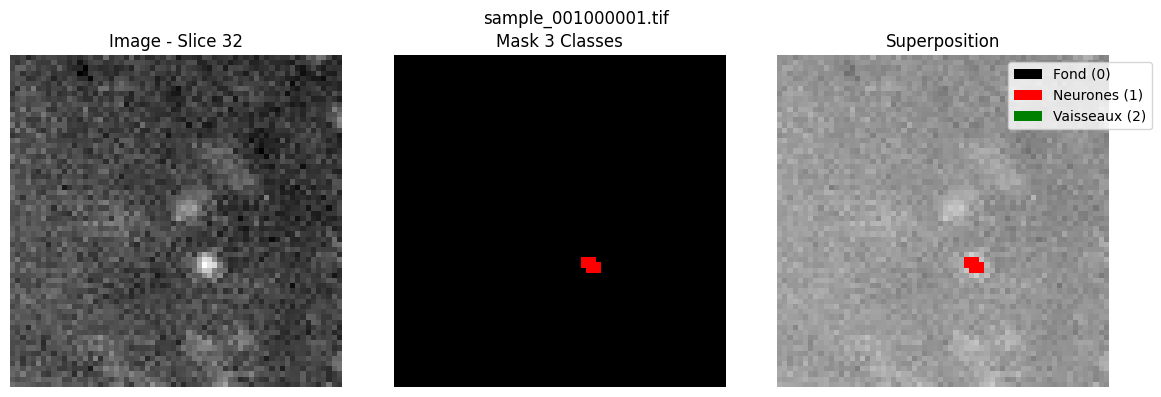

Statistiques du patch:
  Classe 0 (Fond): 261,411
  Classe 1 (Neurones): 733
  Classe 2 (Vaisseaux): 0

--- Patch 2: sample_001000002.tif ---


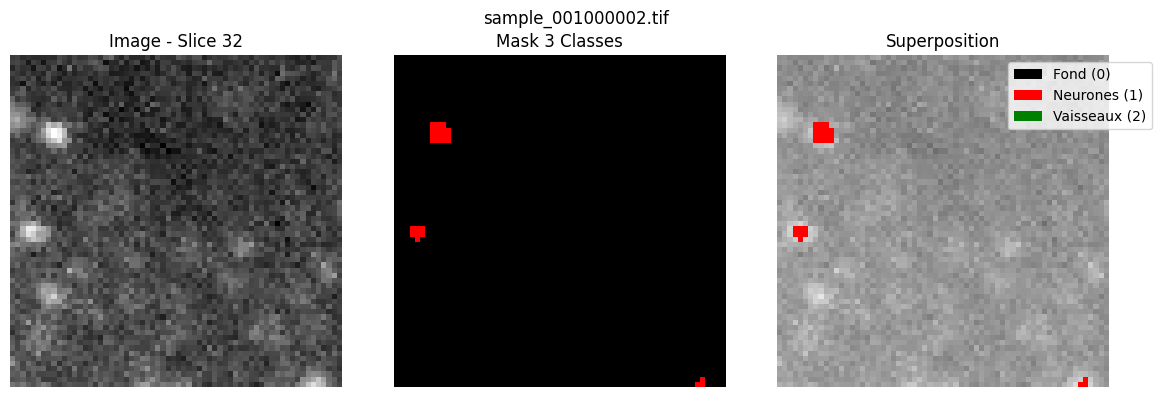

Statistiques du patch:
  Classe 0 (Fond): 261,132
  Classe 1 (Neurones): 1,012
  Classe 2 (Vaisseaux): 0

--- Patch 3: sample_001000003.tif ---


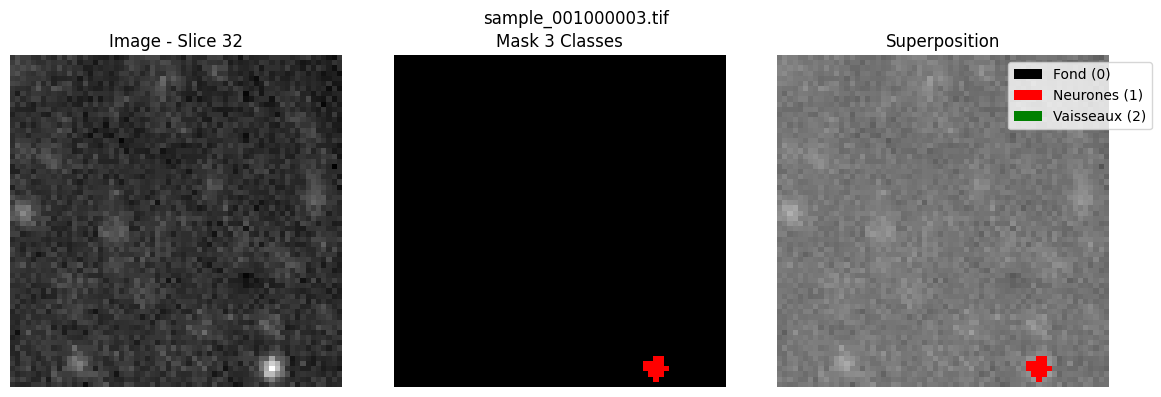

Statistiques du patch:
  Classe 0 (Fond): 260,786
  Classe 1 (Neurones): 1,358
  Classe 2 (Vaisseaux): 0


In [5]:
print("\nVisualisation des premiers patches")
print("-" * 40)

for i in range(min(3, len(image_files))):
    print(f"\n--- Patch {i+1}: {image_files[i].name} ---")
    show_patch_3class(image_files[i], mask_files[i])


Visualisation de patches aléatoires
----------------------------------------

--- Patch aléatoire: sample_066000074.tif ---


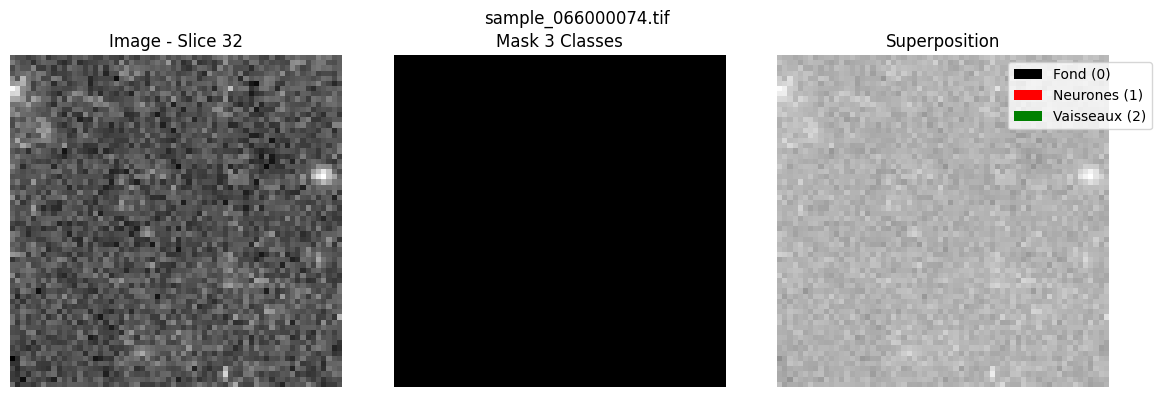

Statistiques du patch:
  Classe 0 (Fond): 261,728
  Classe 1 (Neurones): 416
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_003000015.tif ---


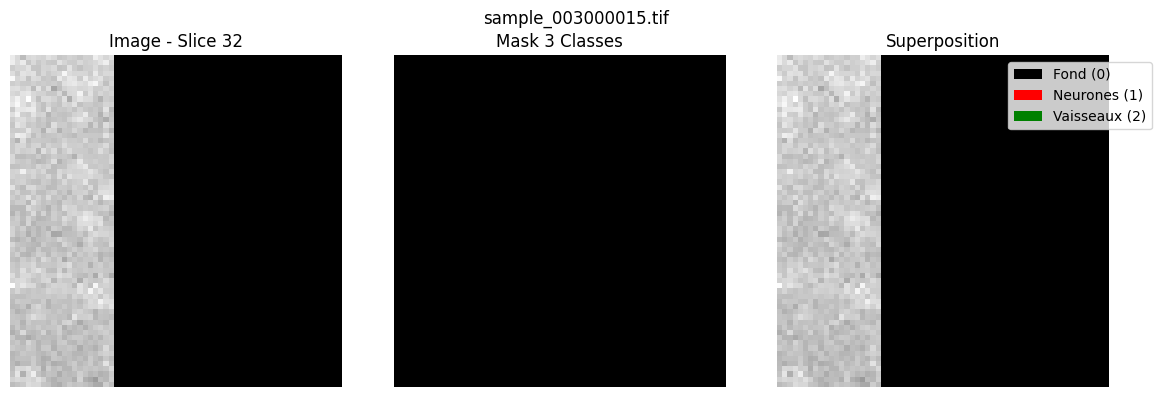

Statistiques du patch:
  Classe 0 (Fond): 262,120
  Classe 1 (Neurones): 24
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_077000895.tif ---


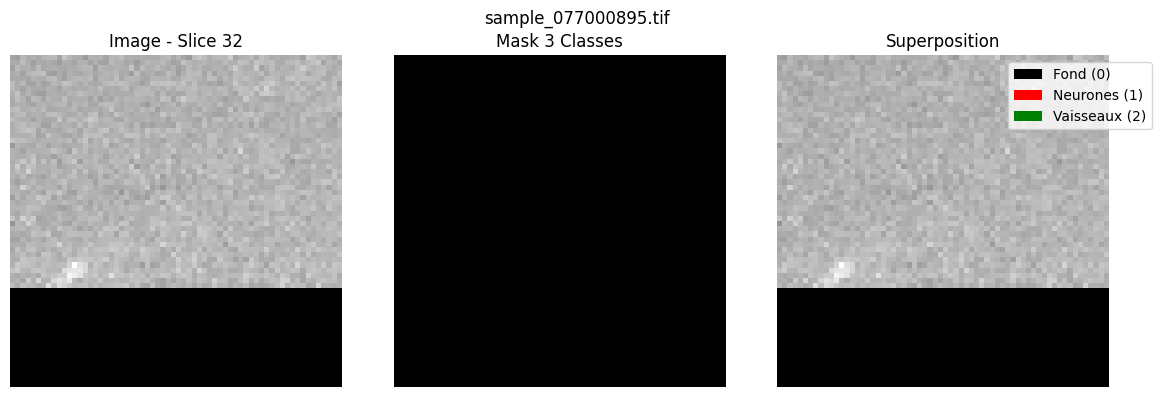

Statistiques du patch:
  Classe 0 (Fond): 262,104
  Classe 1 (Neurones): 40
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_027000009.tif ---


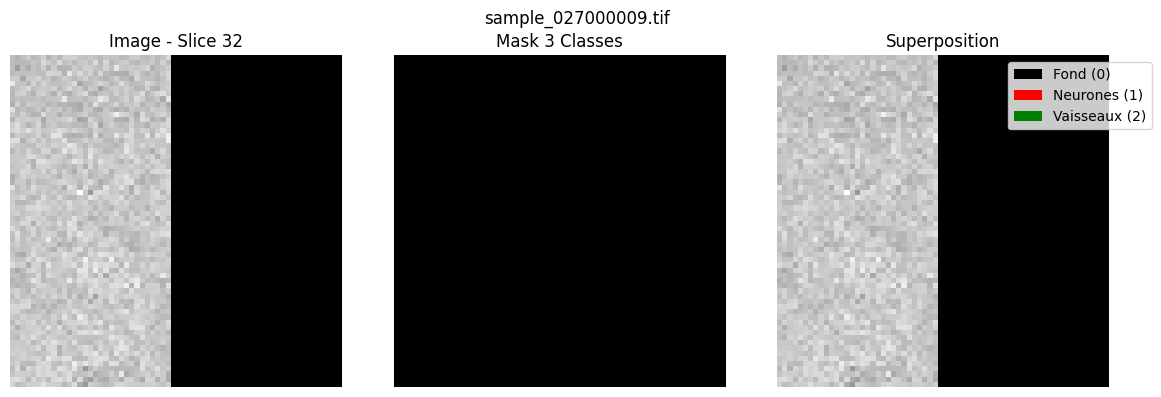

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_033000230.tif ---


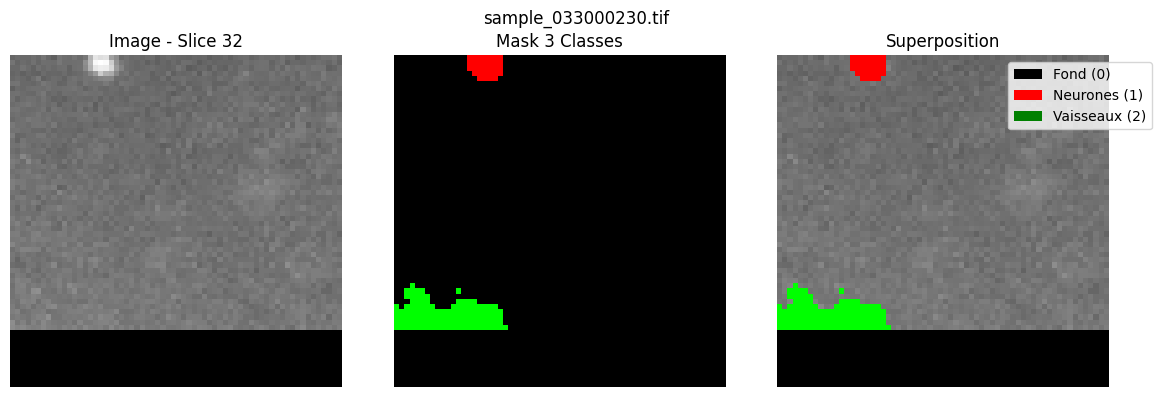

Statistiques du patch:
  Classe 0 (Fond): 207,465
  Classe 1 (Neurones): 1,117
  Classe 2 (Vaisseaux): 53,562

--- Patch aléatoire: sample_083001552.tif ---


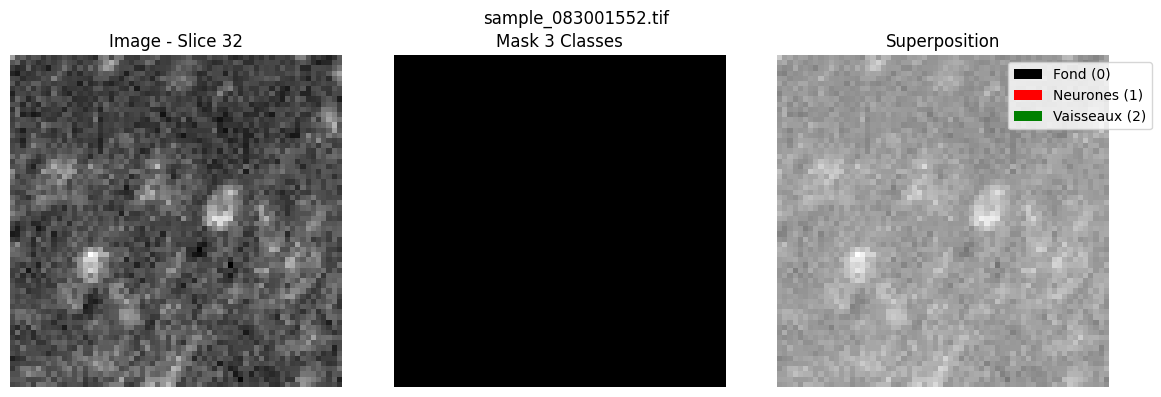

Statistiques du patch:
  Classe 0 (Fond): 262,074
  Classe 1 (Neurones): 70
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_032000343.tif ---


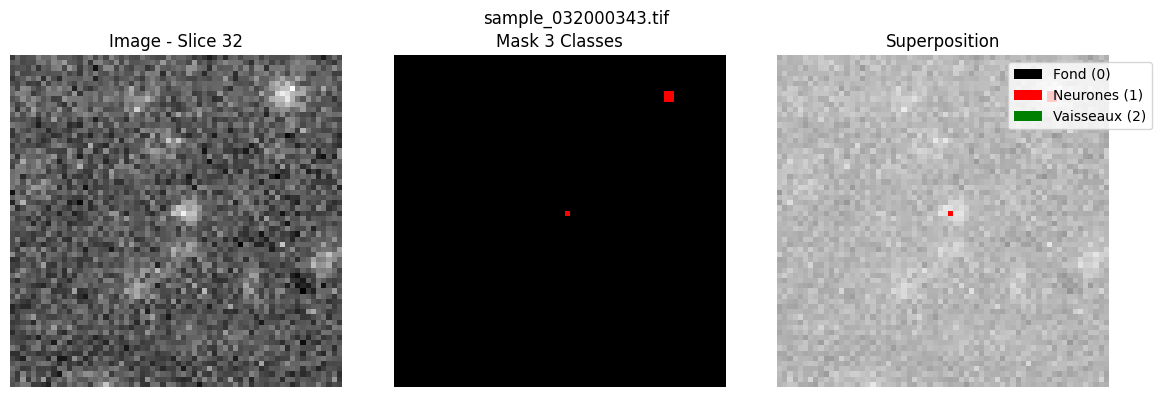

Statistiques du patch:
  Classe 0 (Fond): 261,736
  Classe 1 (Neurones): 408
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_036000062.tif ---


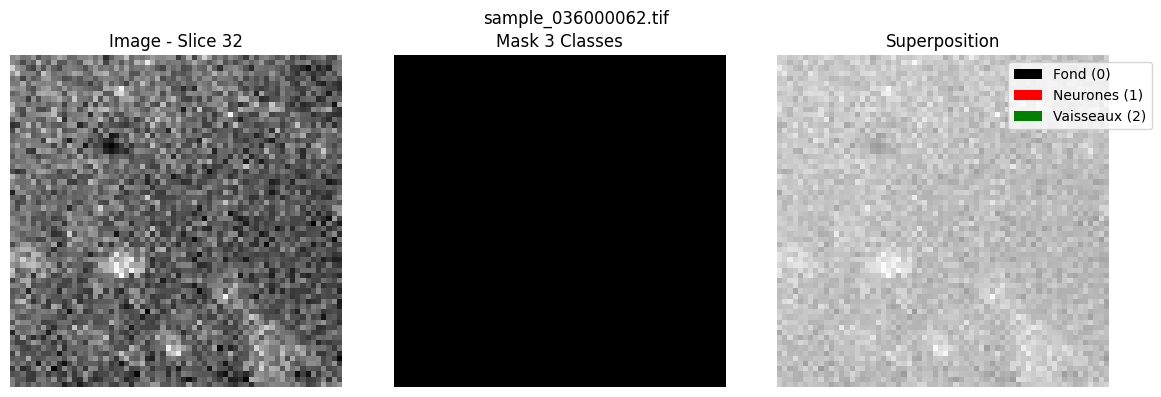

Statistiques du patch:
  Classe 0 (Fond): 261,706
  Classe 1 (Neurones): 438
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_051000020.tif ---


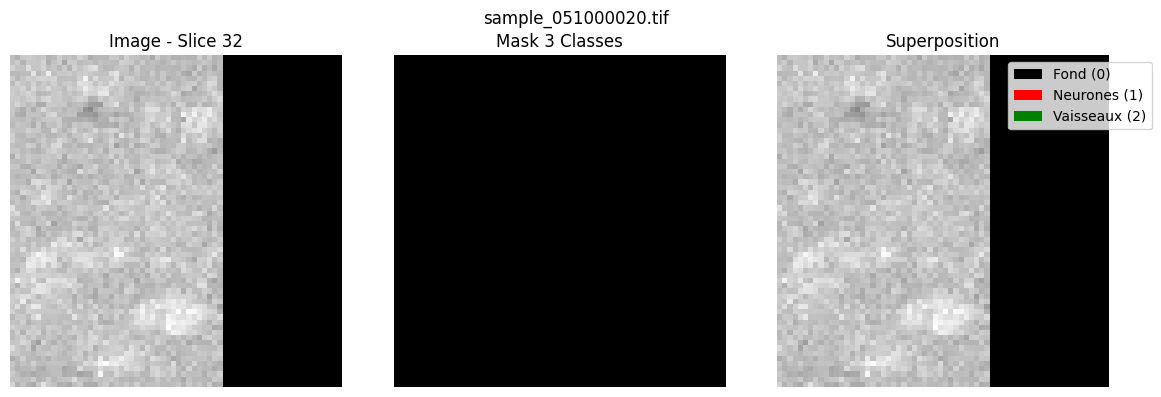

Statistiques du patch:
  Classe 0 (Fond): 262,130
  Classe 1 (Neurones): 14
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_078000427.tif ---


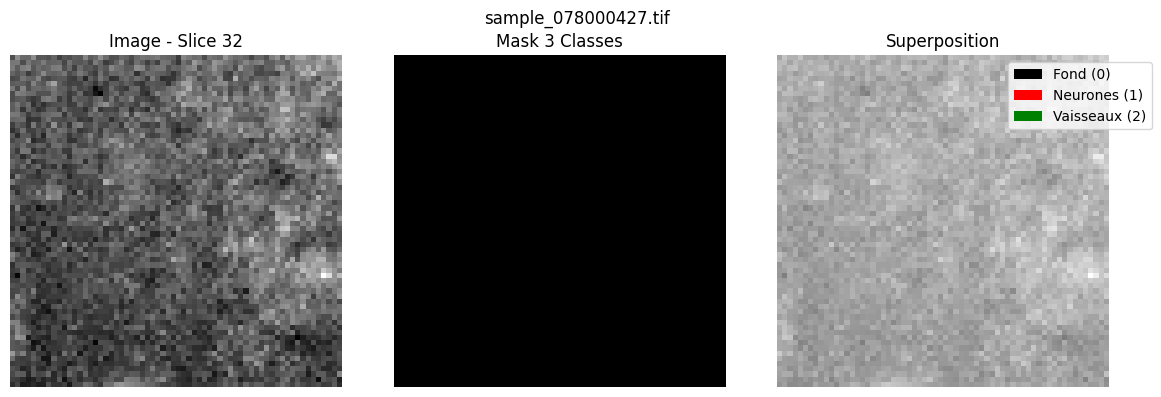

Statistiques du patch:
  Classe 0 (Fond): 262,129
  Classe 1 (Neurones): 15
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_042000078.tif ---


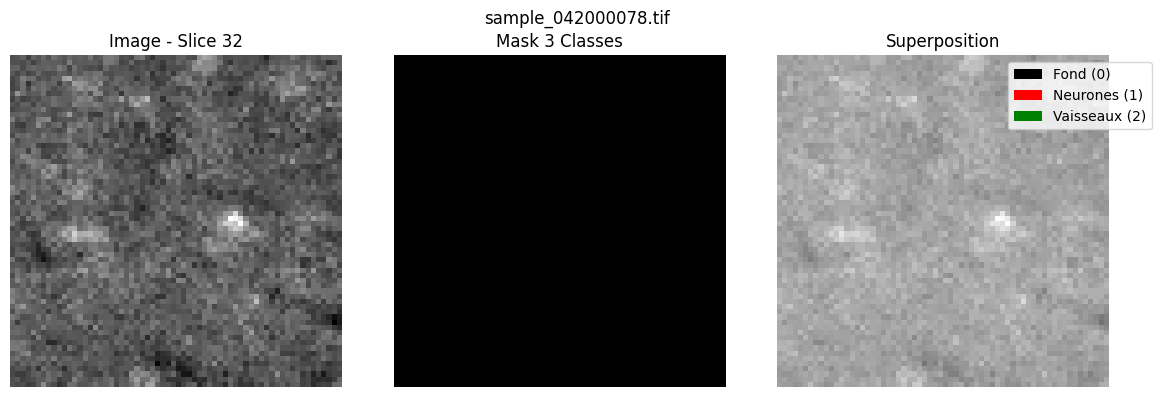

Statistiques du patch:
  Classe 0 (Fond): 262,077
  Classe 1 (Neurones): 67
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_035000461.tif ---


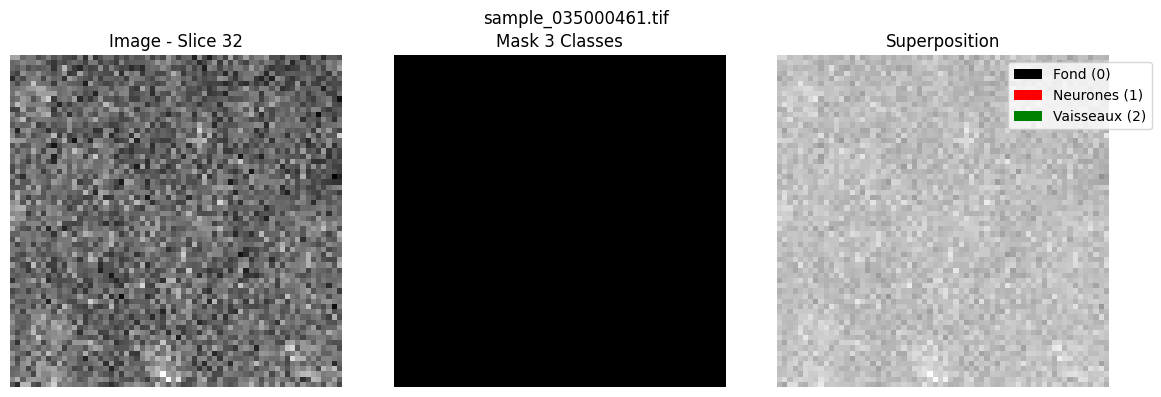

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_020000331.tif ---


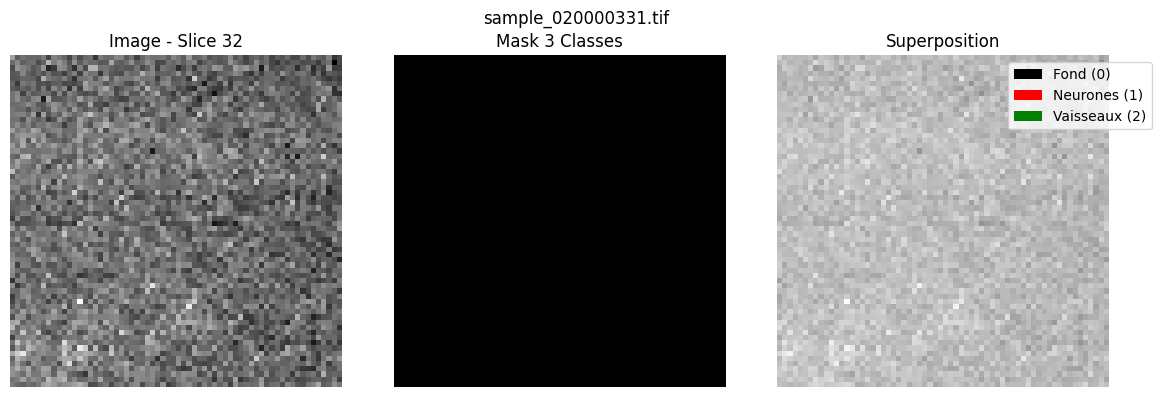

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_080000781.tif ---


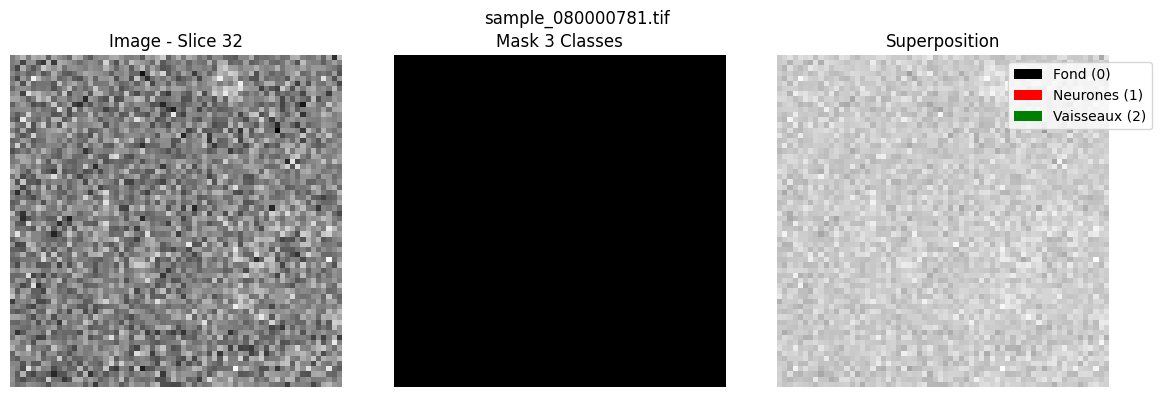

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_083001167.tif ---


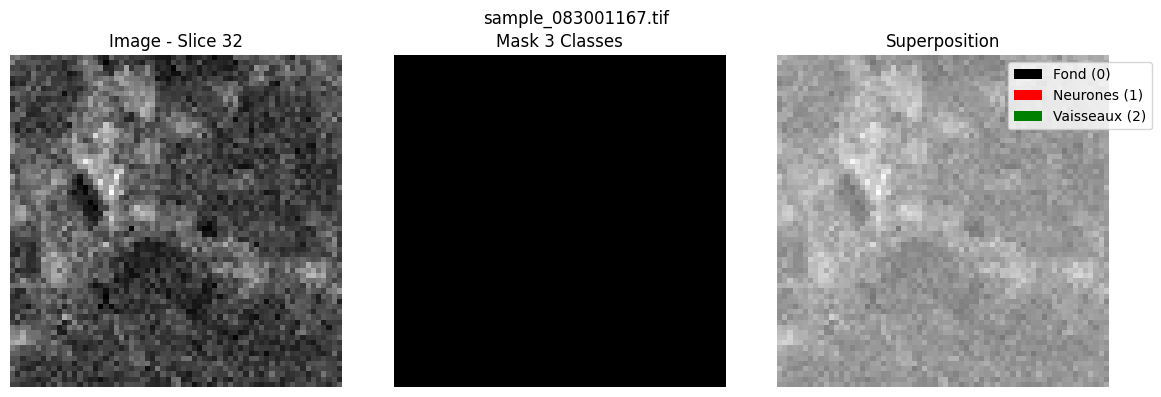

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_020000116.tif ---


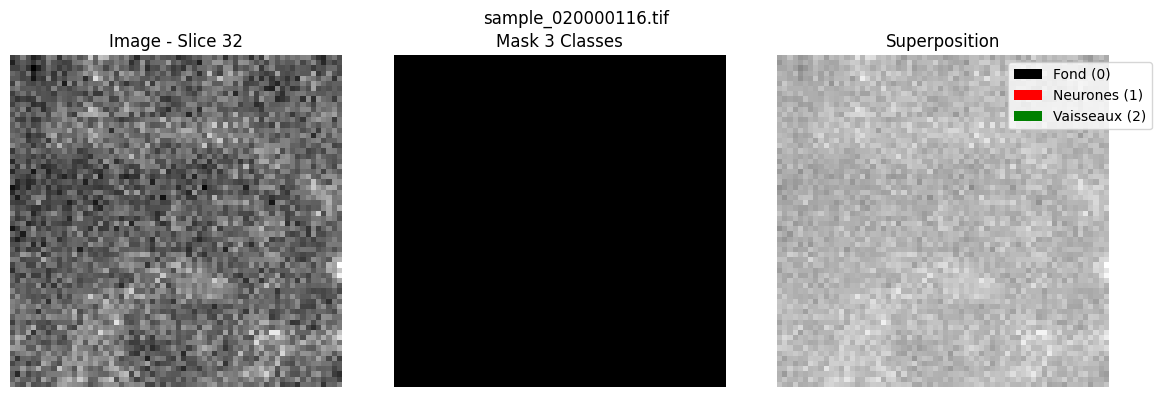

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_067000238.tif ---


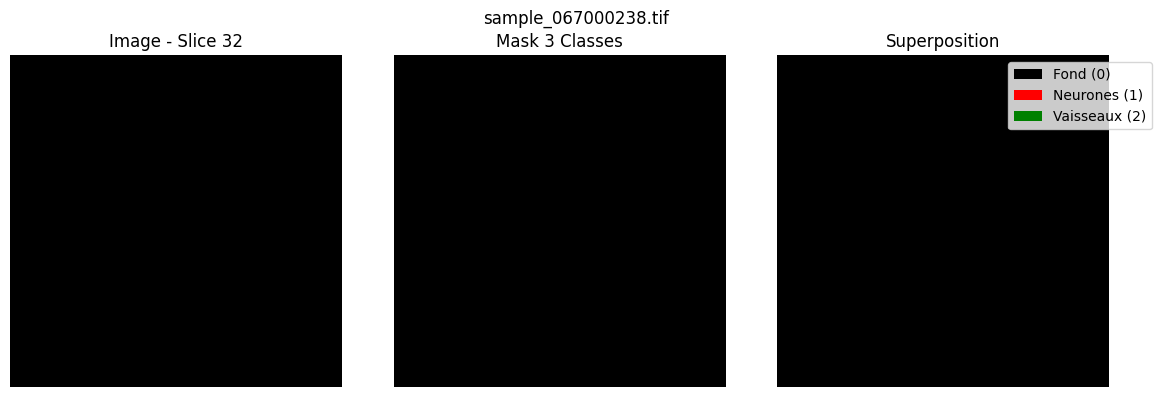

Statistiques du patch:
  Classe 0 (Fond): 262,056
  Classe 1 (Neurones): 88
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_024000184.tif ---


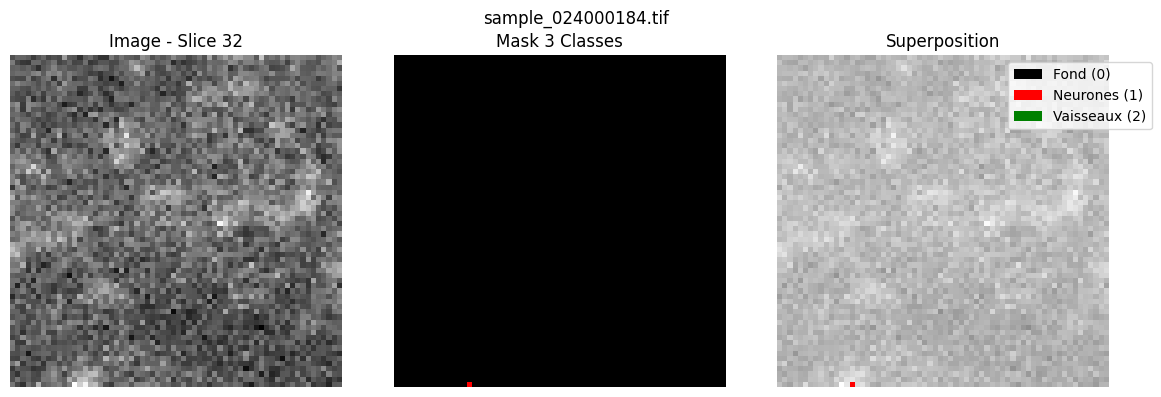

Statistiques du patch:
  Classe 0 (Fond): 260,488
  Classe 1 (Neurones): 1,656
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_032000244.tif ---


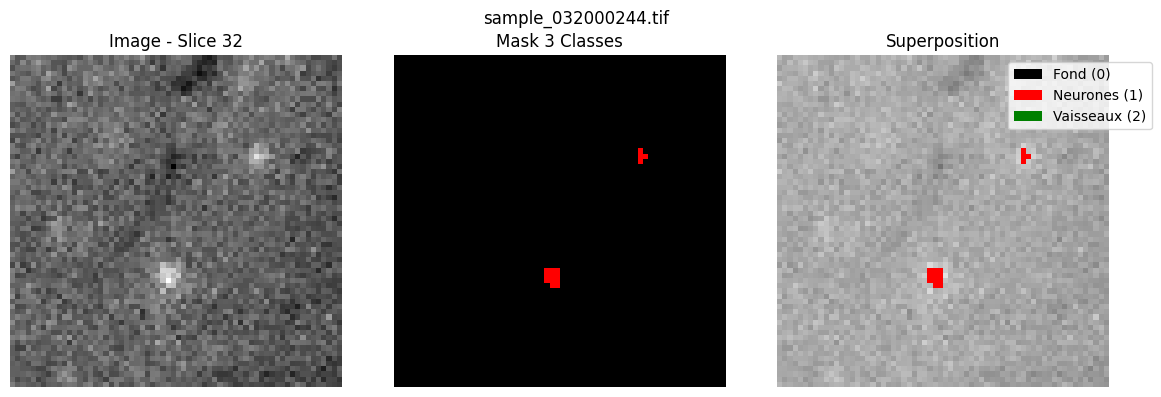

Statistiques du patch:
  Classe 0 (Fond): 261,717
  Classe 1 (Neurones): 427
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_078000245.tif ---


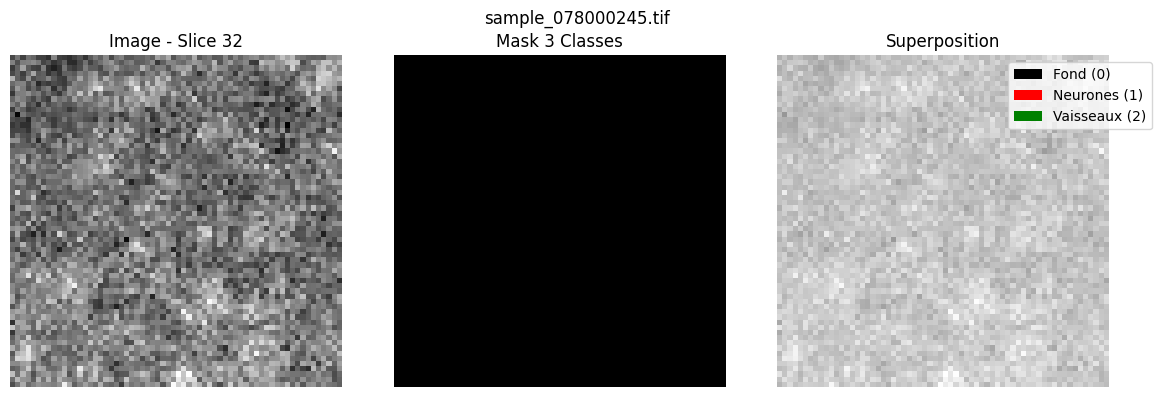

Statistiques du patch:
  Classe 0 (Fond): 261,869
  Classe 1 (Neurones): 275
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_011000051.tif ---


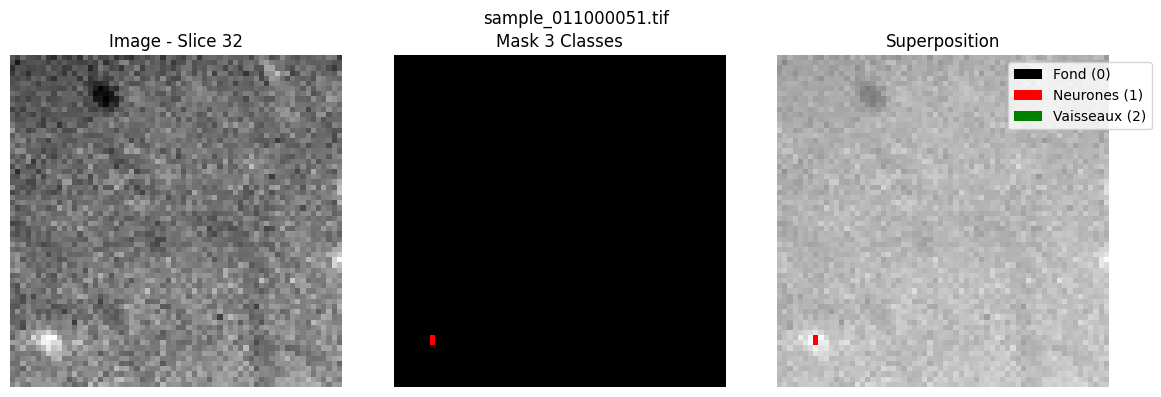

Statistiques du patch:
  Classe 0 (Fond): 262,041
  Classe 1 (Neurones): 103
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_005000032.tif ---


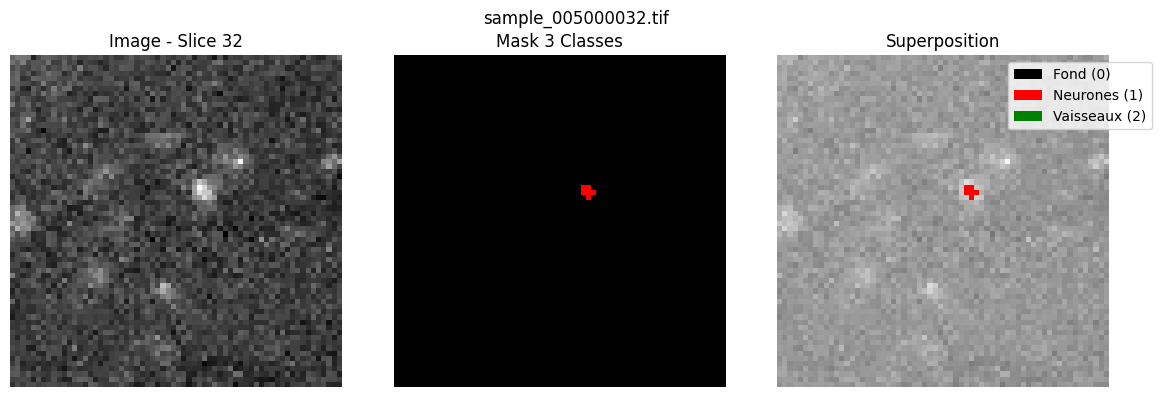

Statistiques du patch:
  Classe 0 (Fond): 261,726
  Classe 1 (Neurones): 418
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_038000411.tif ---


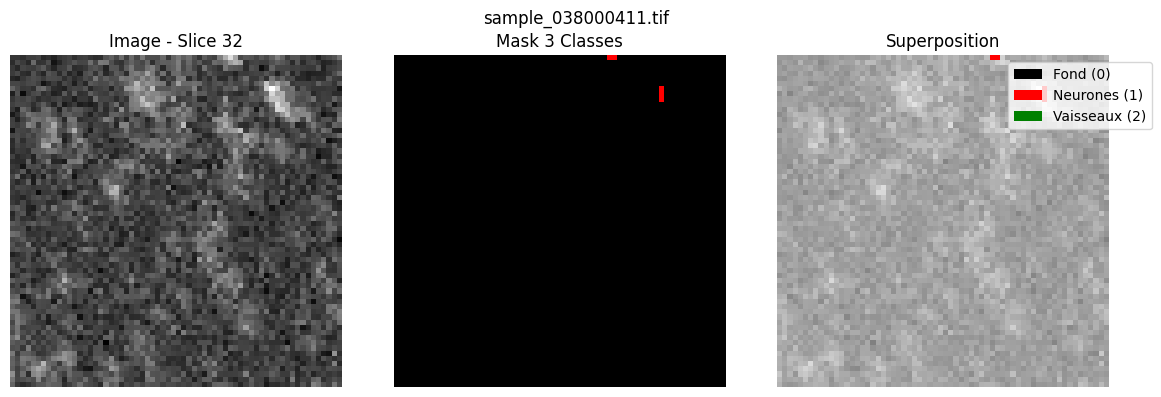

Statistiques du patch:
  Classe 0 (Fond): 260,997
  Classe 1 (Neurones): 1,147
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_043000072.tif ---


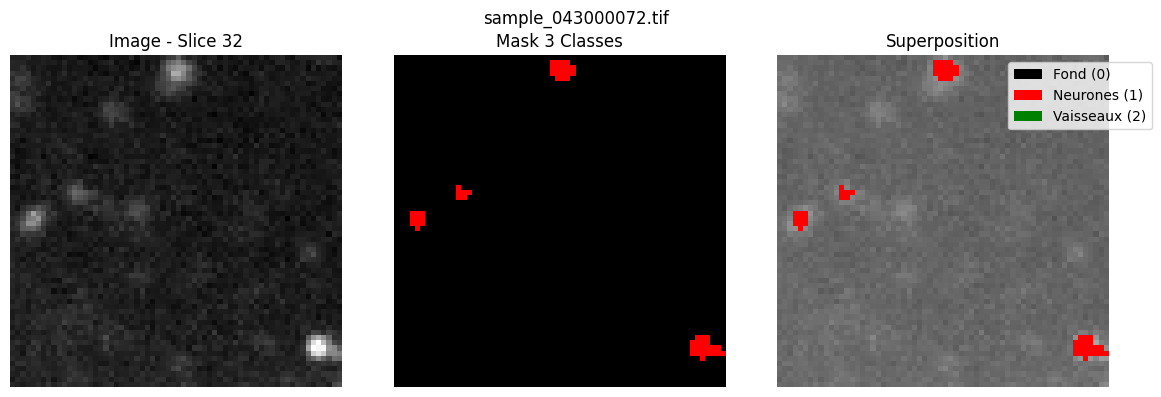

Statistiques du patch:
  Classe 0 (Fond): 256,562
  Classe 1 (Neurones): 5,582
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_077000120.tif ---


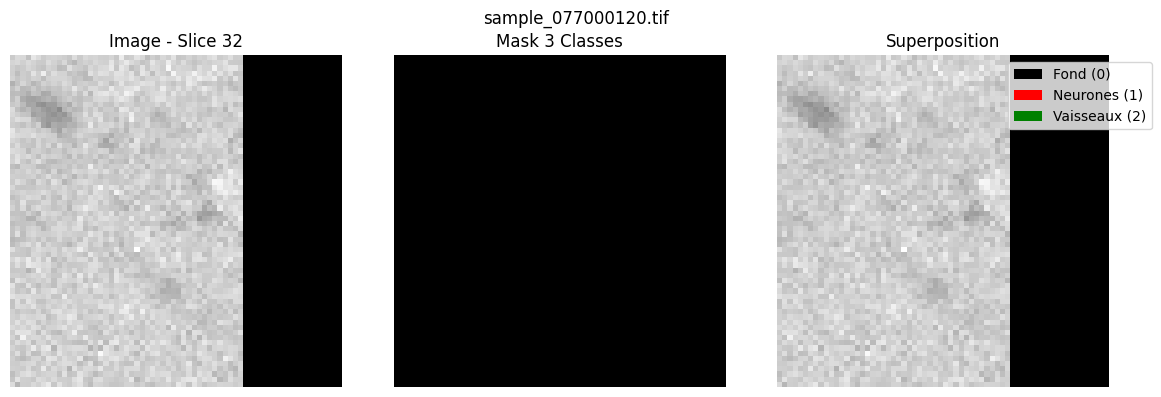

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_080000253.tif ---


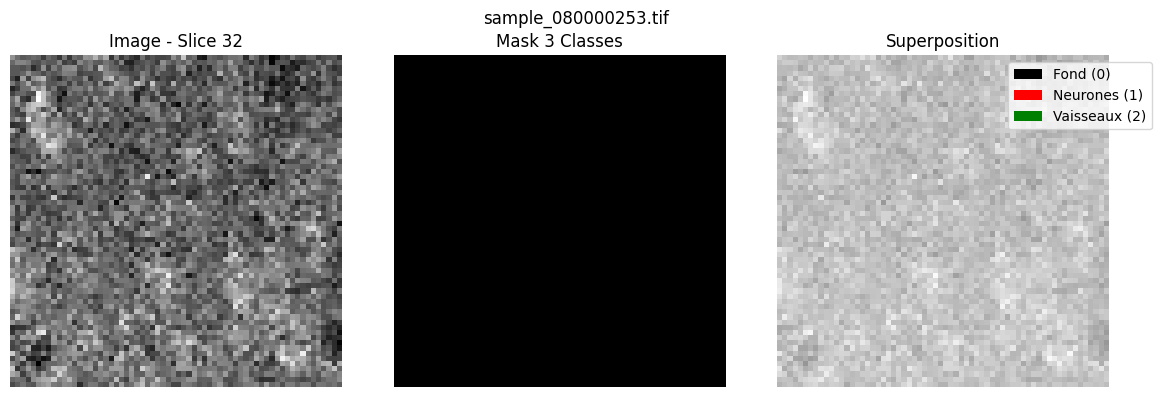

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_005000212.tif ---


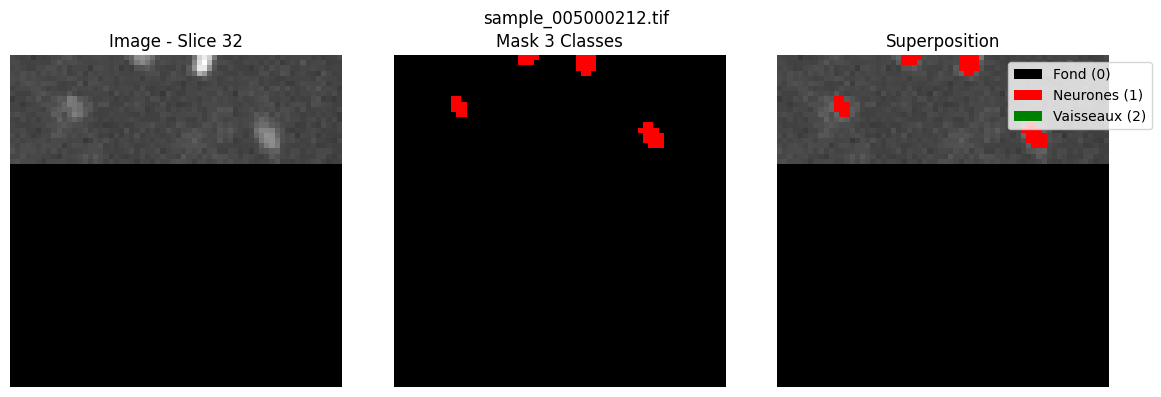

Statistiques du patch:
  Classe 0 (Fond): 261,595
  Classe 1 (Neurones): 549
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_071000308.tif ---


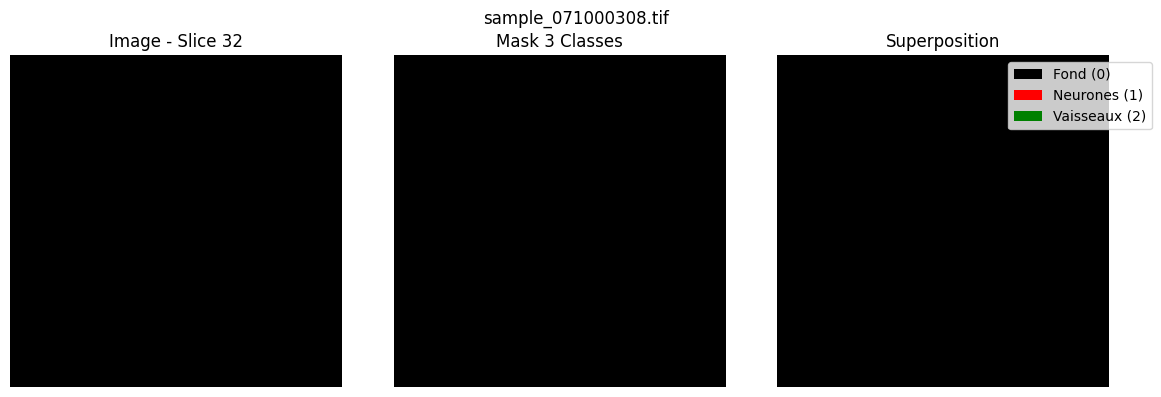

Statistiques du patch:
  Classe 0 (Fond): 261,679
  Classe 1 (Neurones): 465
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_012000042.tif ---


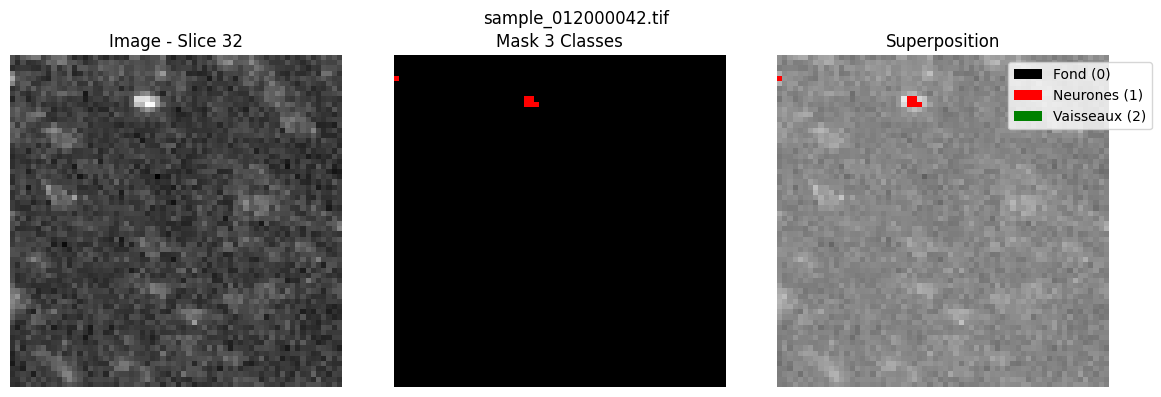

Statistiques du patch:
  Classe 0 (Fond): 261,980
  Classe 1 (Neurones): 164
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_078000190.tif ---


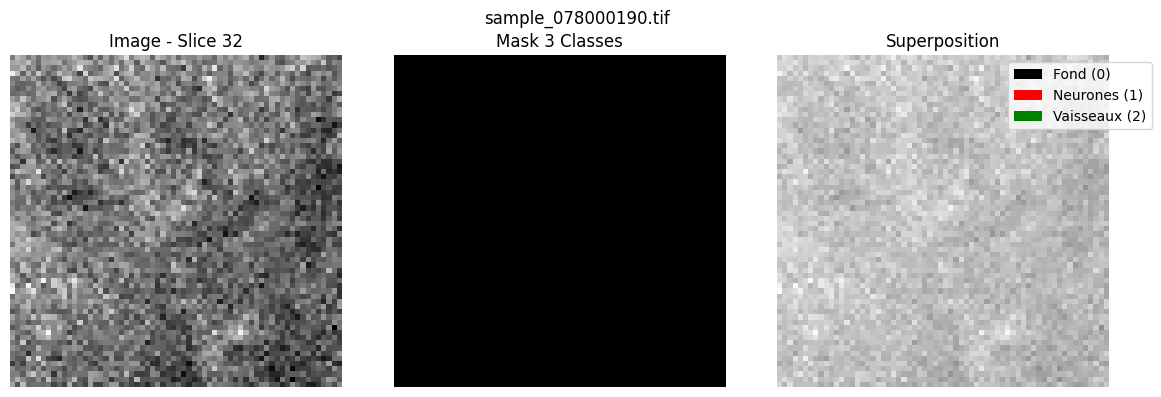

Statistiques du patch:
  Classe 0 (Fond): 262,110
  Classe 1 (Neurones): 34
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_046000118.tif ---


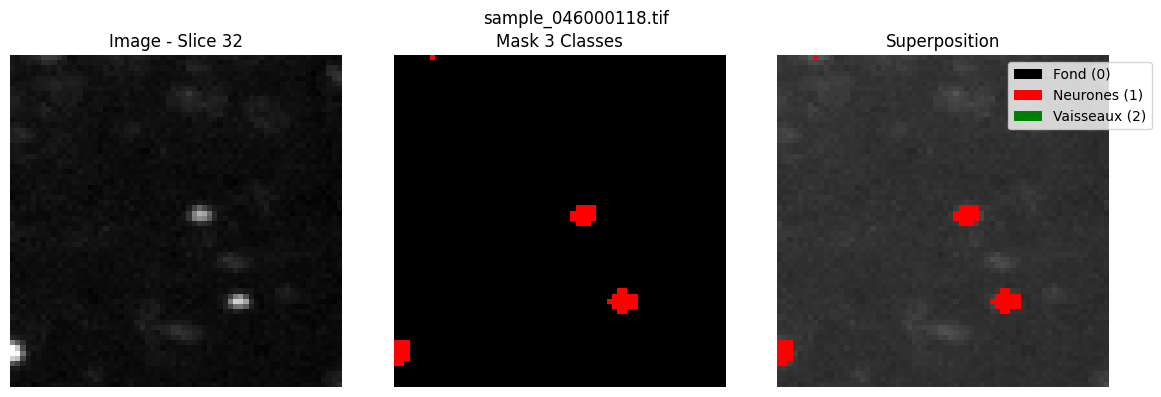

Statistiques du patch:
  Classe 0 (Fond): 260,945
  Classe 1 (Neurones): 1,199
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_035000399.tif ---


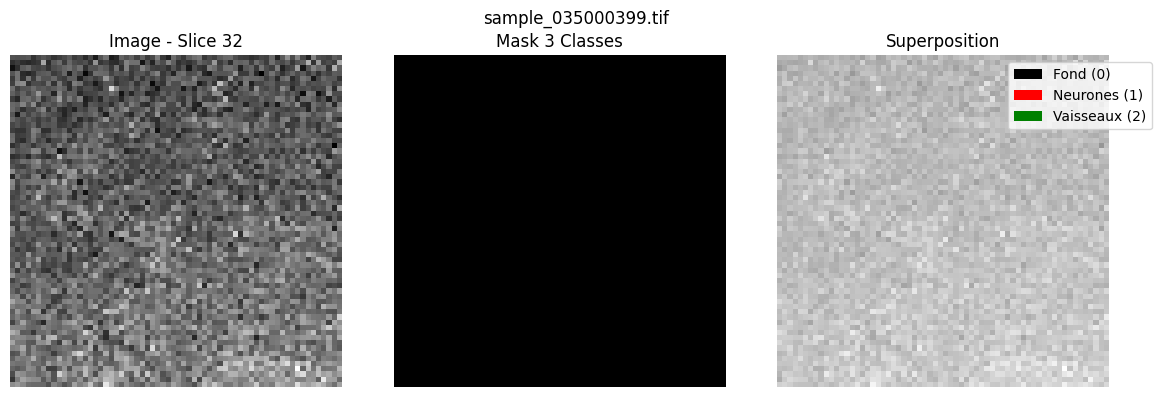

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_029000012.tif ---


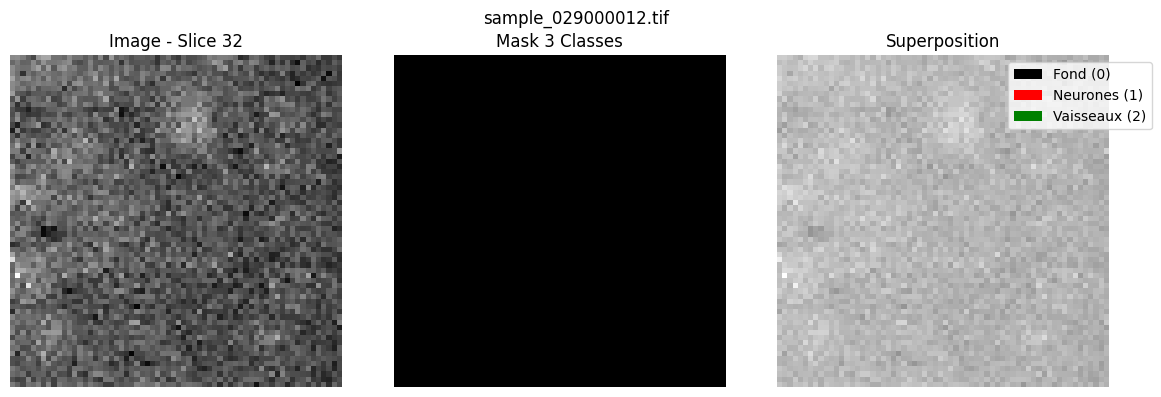

Statistiques du patch:
  Classe 0 (Fond): 261,957
  Classe 1 (Neurones): 187
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_077001986.tif ---


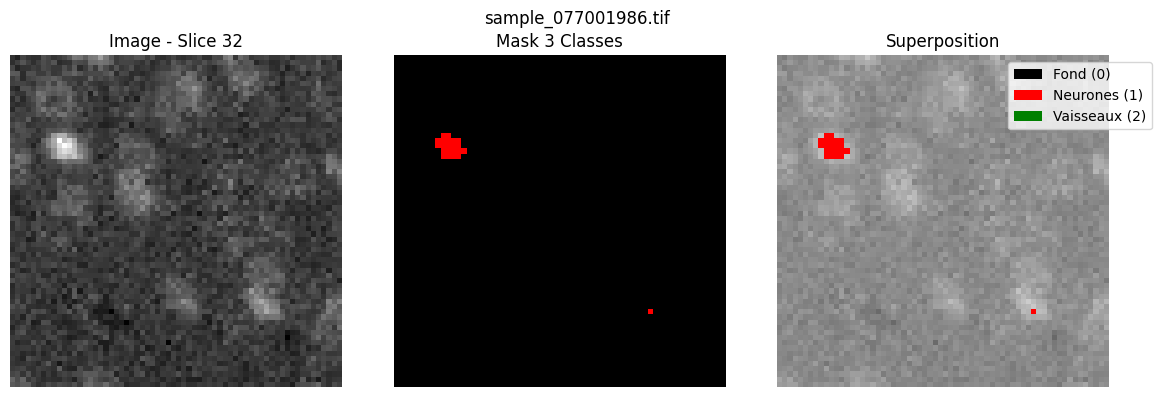

Statistiques du patch:
  Classe 0 (Fond): 261,486
  Classe 1 (Neurones): 658
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_078000593.tif ---


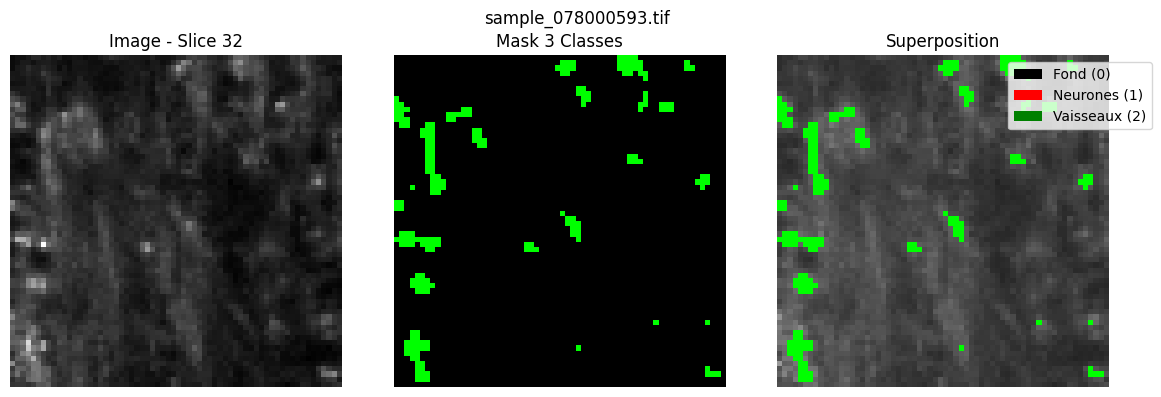

Statistiques du patch:
  Classe 0 (Fond): 253,586
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 8,558

--- Patch aléatoire: sample_077001752.tif ---


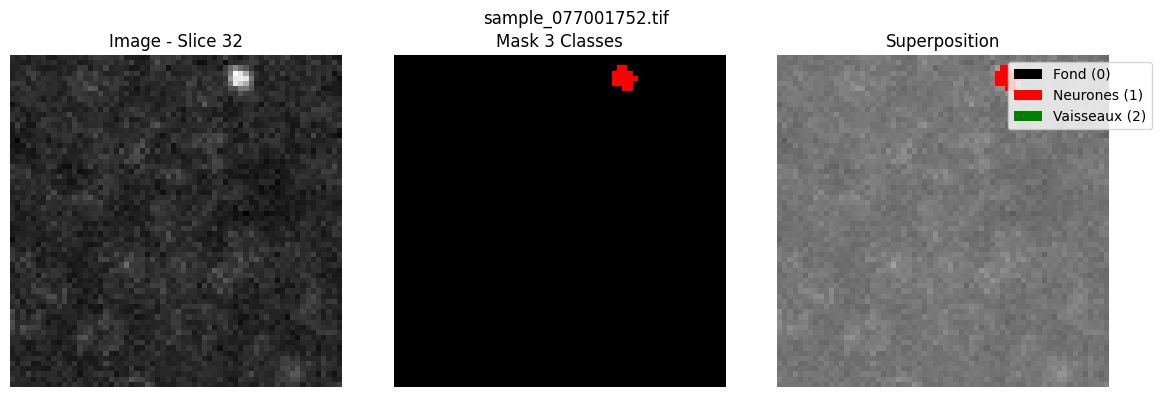

Statistiques du patch:
  Classe 0 (Fond): 260,990
  Classe 1 (Neurones): 1,154
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_001000061.tif ---


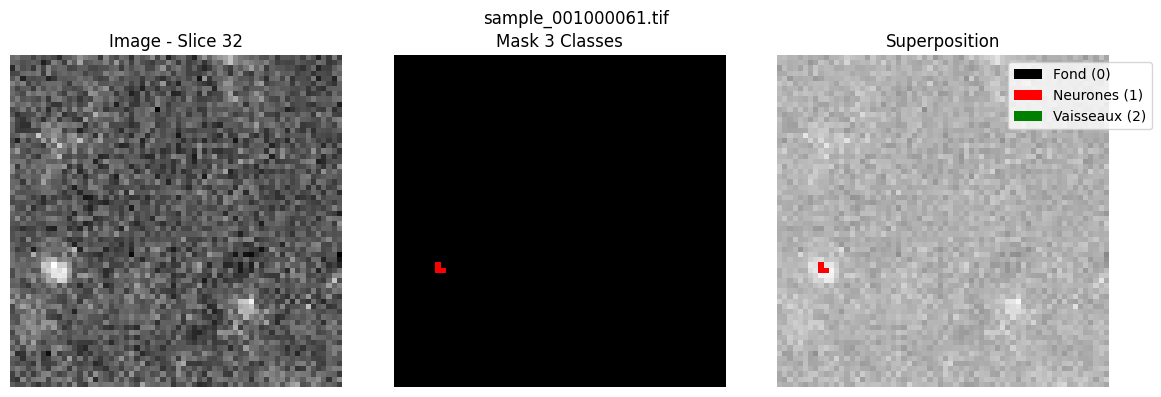

Statistiques du patch:
  Classe 0 (Fond): 262,005
  Classe 1 (Neurones): 139
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_043000088.tif ---


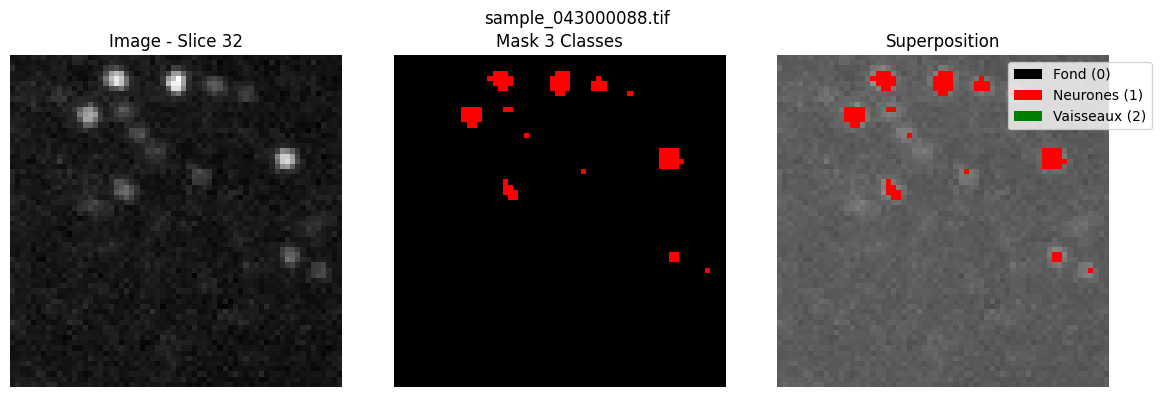

Statistiques du patch:
  Classe 0 (Fond): 256,220
  Classe 1 (Neurones): 5,924
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_077000792.tif ---


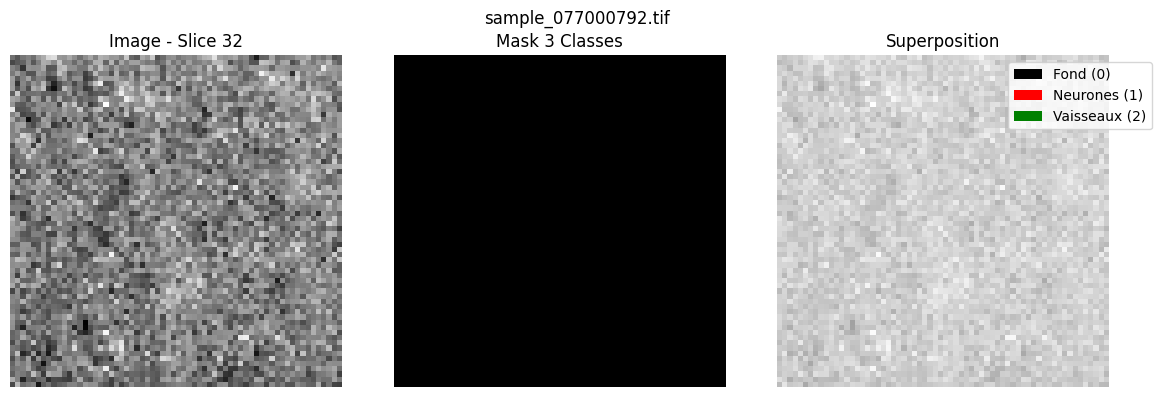

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_038000003.tif ---


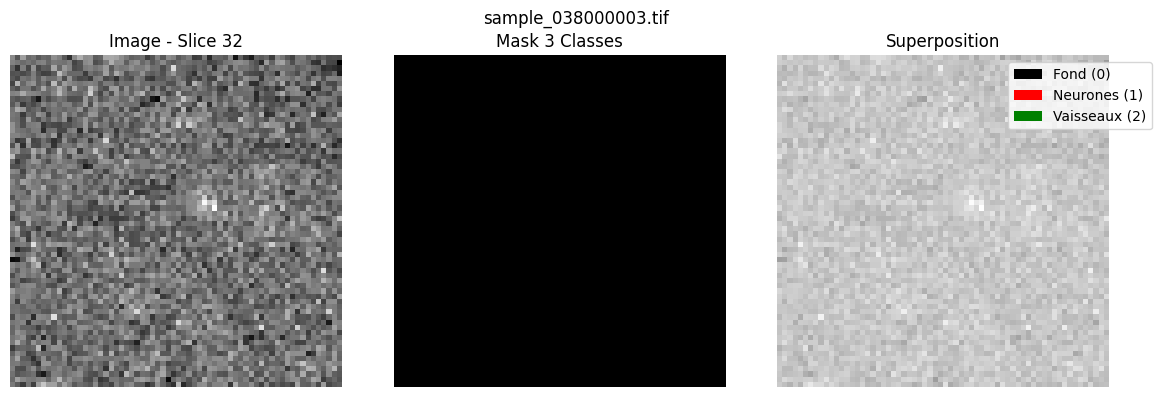

Statistiques du patch:
  Classe 0 (Fond): 262,099
  Classe 1 (Neurones): 45
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_057000148.tif ---


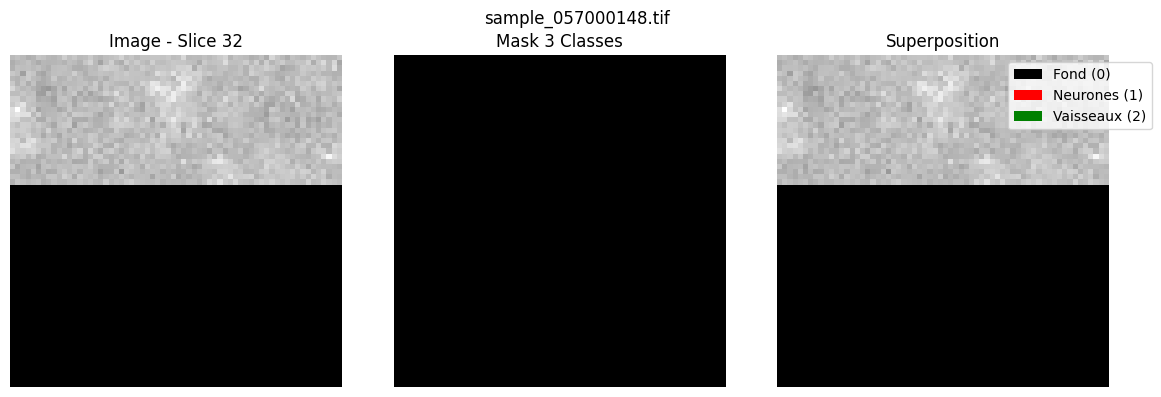

Statistiques du patch:
  Classe 0 (Fond): 262,094
  Classe 1 (Neurones): 50
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_067000147.tif ---


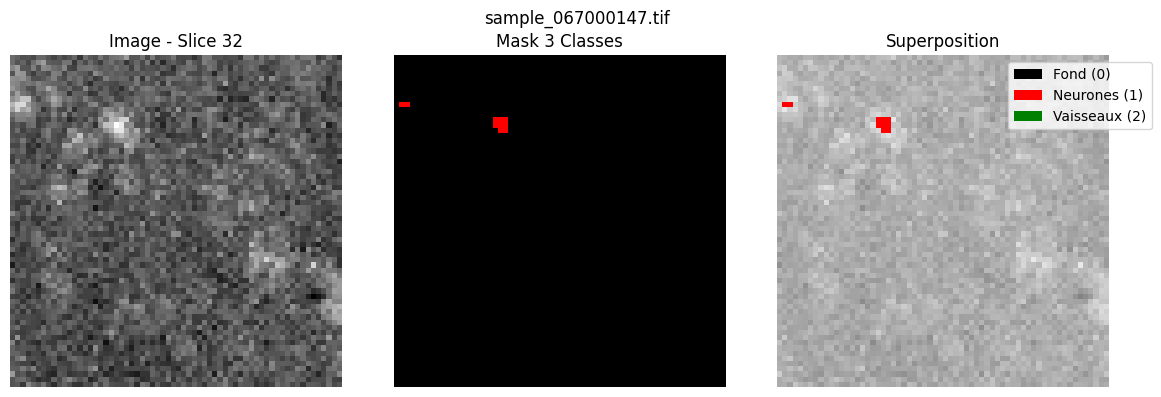

Statistiques du patch:
  Classe 0 (Fond): 261,555
  Classe 1 (Neurones): 589
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_018000052.tif ---


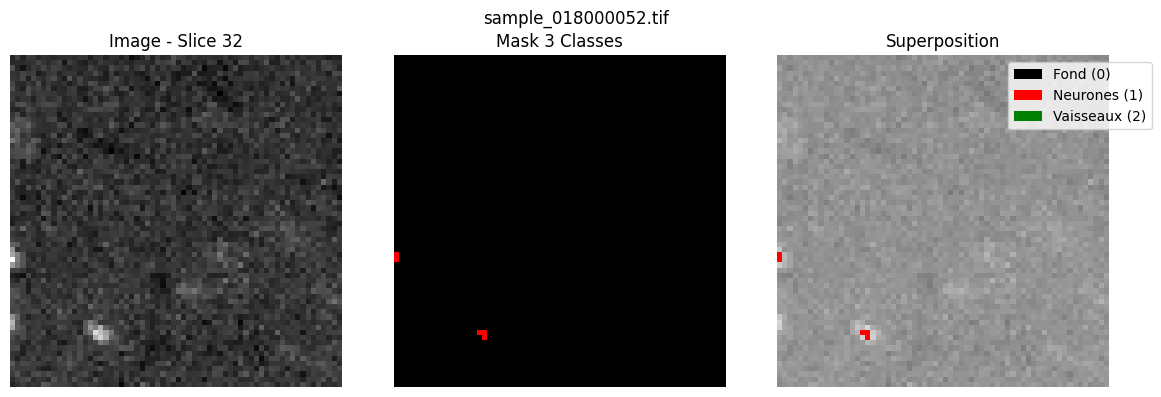

Statistiques du patch:
  Classe 0 (Fond): 261,706
  Classe 1 (Neurones): 438
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_083001639.tif ---


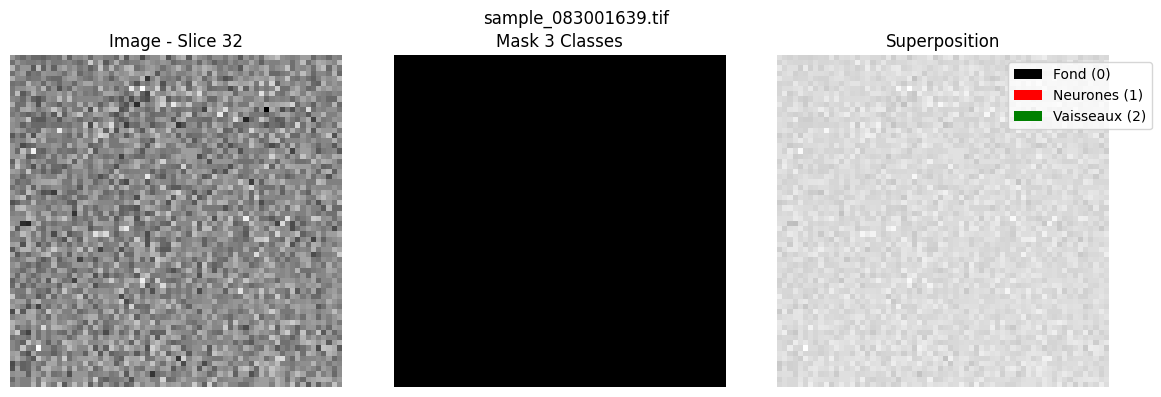

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_077001235.tif ---


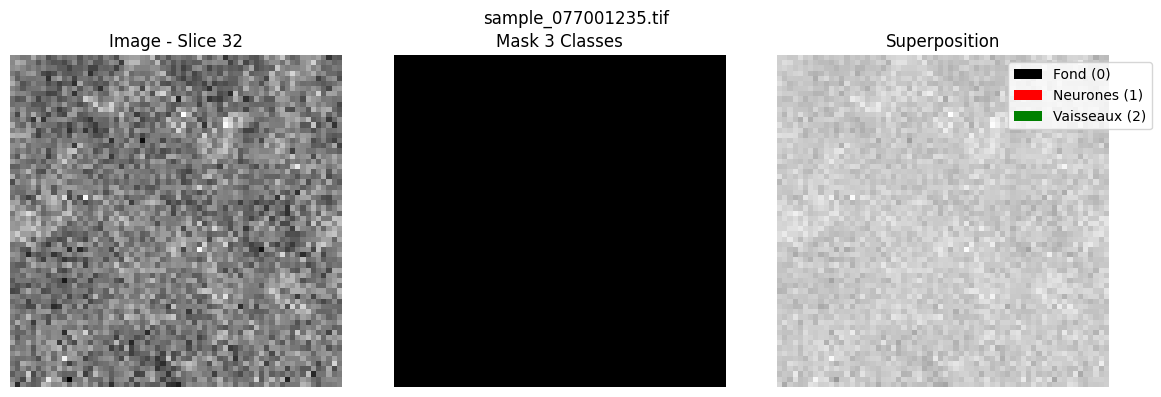

Statistiques du patch:
  Classe 0 (Fond): 261,963
  Classe 1 (Neurones): 181
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_026000328.tif ---


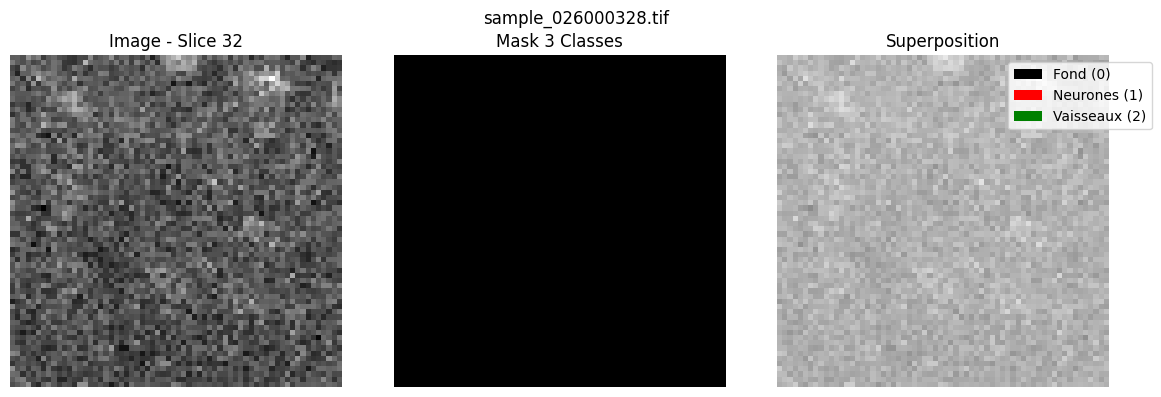

Statistiques du patch:
  Classe 0 (Fond): 261,994
  Classe 1 (Neurones): 150
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_037000251.tif ---


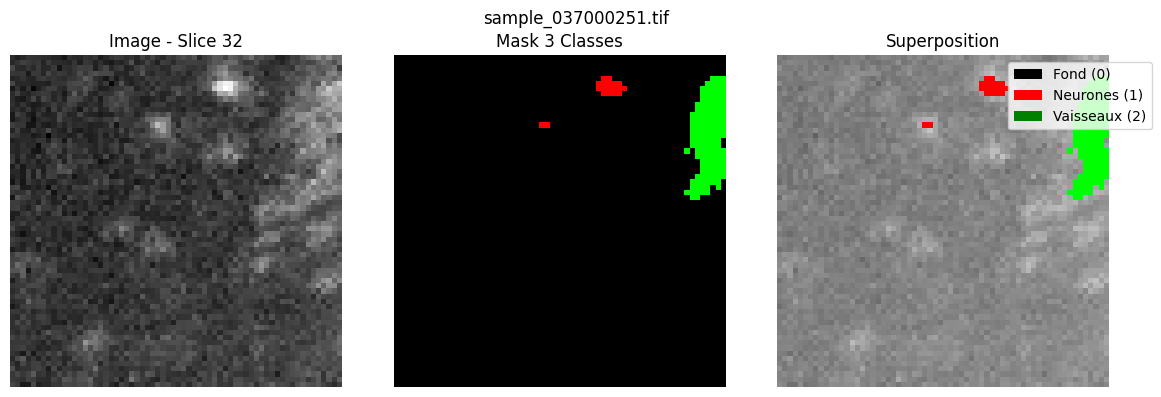

Statistiques du patch:
  Classe 0 (Fond): 258,581
  Classe 1 (Neurones): 701
  Classe 2 (Vaisseaux): 2,862

--- Patch aléatoire: sample_032000406.tif ---


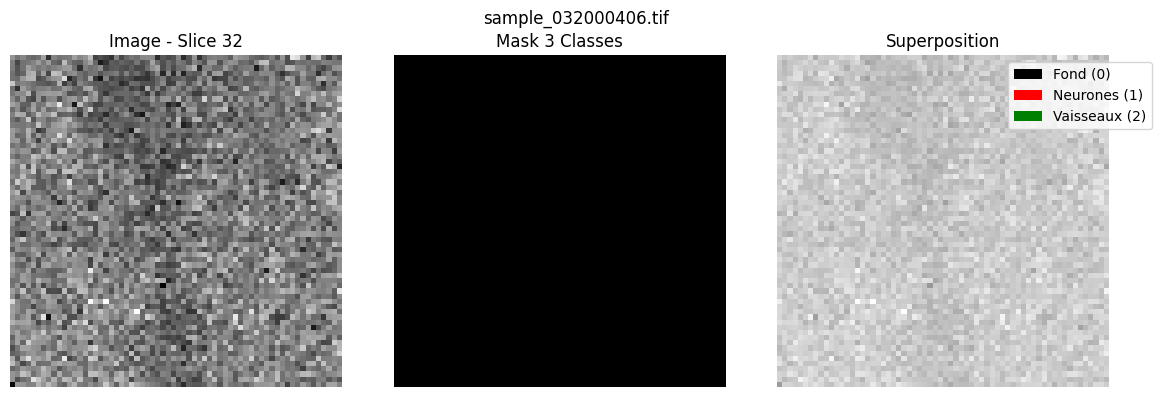

Statistiques du patch:
  Classe 0 (Fond): 262,073
  Classe 1 (Neurones): 71
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_083001477.tif ---


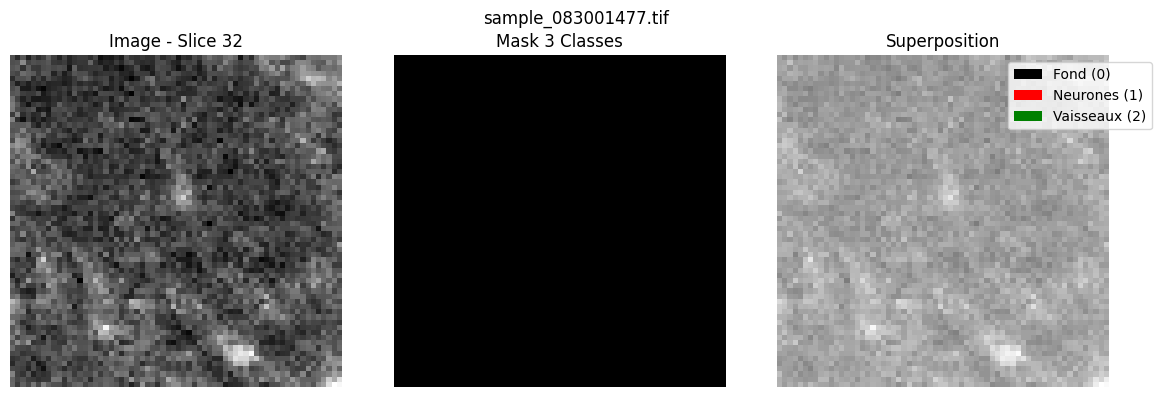

Statistiques du patch:
  Classe 0 (Fond): 262,144
  Classe 1 (Neurones): 0
  Classe 2 (Vaisseaux): 0

--- Patch aléatoire: sample_077001114.tif ---


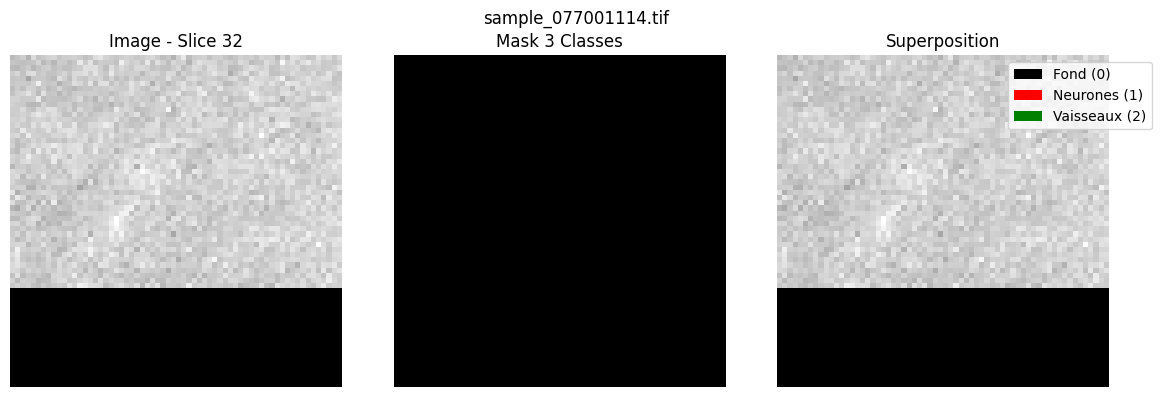

Statistiques du patch:
  Classe 0 (Fond): 262,077
  Classe 1 (Neurones): 67
  Classe 2 (Vaisseaux): 0


In [7]:
print("\nVisualisation de patches aléatoires")
print("-" * 40)

random_indices = random.sample(range(len(image_files)), min(50, len(image_files)))

for idx in random_indices:
    print(f"\n--- Patch aléatoire: {image_files[idx].name} ---")
    show_patch_3class(image_files[idx], mask_files[idx])